# Initial reasoning-phase classifier experiment

Train one LTO-inspired binary classifier on complete pre-answer reasoning trajectories, then evaluate that same classifier on early, early+middle, and reasoning-full representations of held-out rollouts.

## 1. Configuration and reproducibility

In [1]:
import json
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import DataLoader, Dataset, SequentialSampler
from tqdm.auto import tqdm

from google.colab import drive

drive.mount("/content/gdrive")

ROOT = Path("/content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean")
RAW_DIR = ROOT / "full" / "raw_layer_outputs"
RECORDS_DIR = ROOT / "full" / "records"
OUTPUT_DIR = ROOT / "probe_training_initial_reasoning_phase"
FEATURE_DIR = OUTPUT_DIR / "reasoning_phase_features_raw_unnormalized"

SEED = 42
EPOCHS = 10
BATCH_SIZE = 32
LEARNING_RATE = 5e-6
TEST_SIZE = 0.20

EXPECTED_ROLLOUTS = 9_780
EXPECTED_CORRECT = 6_164
EXPECTED_INCORRECT = 3_616
N_LAYERS = 26
D_MODEL = 1152
N_HEADS = 4
FFN_DIM = 6912
DROPOUT = 0.1
ENCODER_LAYERS = 2
CACHE_DTYPE = np.dtype(np.float16)
CACHE_VALIDATION_BATCH_SIZE = 256

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_everything(SEED)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FEATURE_DIR.mkdir(parents=True, exist_ok=True)
print({"device": str(DEVICE), "seed": SEED, "feature_cache": str(FEATURE_DIR)})

Mounted at /content/gdrive
{'device': 'cuda', 'seed': 42, 'feature_cache': '/content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/probe_training_initial_reasoning_phase/reasoning_phase_features_raw_unnormalized'}


## 2. Dataset indexing and validation

In [2]:
def parse_correct(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, (int, float, np.number)) and not isinstance(
        value, (bool, np.bool_)
    ):
        if np.isfinite(value) and float(value) in {0.0, 1.0}:
            return bool(int(value))
        return None
    if isinstance(value, str):
        normalized = value.strip().lower()
        if normalized in {"true", "correct", "1", "yes"}:
            return True
        if normalized in {"false", "incorrect", "0", "no"}:
            return False
    return None


def label_from_value(value):
    correct = parse_correct(value)
    if correct is True:
        return "Correct"
    if correct is False:
        return "Incorrect"
    return "Unresolved"


def to_python(value):
    if isinstance(value, np.ndarray):
        return to_python(value.tolist())
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, dict):
        return {str(key): to_python(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_python(item) for item in value]
    return value


def parse_ranges(value):
    if isinstance(value, str):
        try:
            value = json.loads(value)
        except json.JSONDecodeError:
            return None
    value = to_python(value)
    return value if isinstance(value, dict) else None


def integer_value(value):
    if isinstance(value, (bool, np.bool_)):
        return None
    if isinstance(value, (int, np.integer)):
        return int(value)
    if (
        isinstance(value, (float, np.floating))
        and np.isfinite(value)
        and float(value).is_integer()
    ):
        return int(value)
    return None


def phase_range_issue(value, boxed_token_start, token_count=None):
    ranges = parse_ranges(value)
    if ranges is None:
        return "missing_phase_ranges"

    boundary = integer_value(boxed_token_start)
    if boundary is None or boundary <= 0:
        return "invalid_boxed_token_start"

    parsed = {}
    for phase in ("early", "middle", "late"):
        bounds = ranges.get(phase)
        if not isinstance(bounds, (list, tuple)):
            return f"missing_{phase}"
        if len(bounds) != 2:
            return f"malformed_{phase}"
        start, end = map(integer_value, bounds)
        if start is None or end is None:
            return f"non_integer_{phase}"
        if start < 0:
            return f"negative_bound_{phase}"
        if end <= start:
            return f"empty_or_reversed_{phase}"
        parsed[phase] = (start, end)

    if parsed["early"][0] != 0:
        return "early_does_not_start_at_zero"
    if parsed["early"][1] != parsed["middle"][0]:
        return "early_middle_not_contiguous"
    if parsed["middle"][1] != parsed["late"][0]:
        return "middle_late_not_contiguous"
    if parsed["late"][1] != boundary:
        return "late_does_not_end_at_boxed_token_start"

    if token_count is not None:
        count = integer_value(token_count)
        if count is None or count <= 0:
            return "invalid_hidden_state_token_count"
        if any(start >= count or end > count for start, end in parsed.values()):
            return "phase_bound_exceeds_token_count"
    return None


def validated_phase_ranges(value, boxed_token_start, token_count, rollout_key):
    issue = phase_range_issue(value, boxed_token_start, token_count)
    if issue is not None:
        raise ValueError(
            f"Rollout {rollout_key!r} has invalid phase ranges: {issue}; "
            f"ranges={to_python(value)!r}, boxed_token_start="
            f"{boxed_token_start!r}, token_count={token_count}."
        )
    ranges = parse_ranges(value)
    return {
        phase: tuple(integer_value(bound) for bound in ranges[phase])
        for phase in ("early", "middle", "late")
    }


def require_columns(table, columns, table_name):
    missing = set(columns) - set(table.columns)
    if missing:
        raise ValueError(f"{table_name} is missing columns: {sorted(missing)}.")


def require_unique_rollout_keys(table, table_name):
    require_columns(table, ["key"], table_name)
    duplicated = table["key"].duplicated(keep=False)
    if duplicated.any():
        examples = table.loc[duplicated, "key"].astype(str).unique()[:10].tolist()
        raise ValueError(f"{table_name} contains duplicate rollout keys: {examples}.")


metadata_path = ROOT / "analysis_cache_spectral" / "rollout_metadata.parquet"
if metadata_path.is_file():
    metadata = pd.read_parquet(metadata_path).copy()
    if "key" not in metadata:
        if "raw_path" not in metadata:
            raise ValueError("Metadata needs either a key or raw_path column.")
        metadata["key"] = metadata["raw_path"].map(
            lambda value: Path(str(value)).stem
        )
    if "sample_id" not in metadata:
        metadata["sample_id"] = (
            metadata["prompt_id"]
            if "prompt_id" in metadata
            else metadata["key"].map(lambda value: str(value).split("_")[0])
        )
    if "rollout_id" not in metadata:
        metadata["rollout_id"] = metadata["key"]
    if "label" in metadata:
        metadata["label"] = metadata["label"].map(label_from_value)
    elif "correct" in metadata:
        metadata["label"] = metadata["correct"].map(label_from_value)
    else:
        raise ValueError("Metadata has neither a label nor a correct column.")

    require_unique_rollout_keys(metadata, "metadata table")
    missing_boundaries = [
        column
        for column in ("phase_ranges", "boxed_token_start")
        if column not in metadata
    ]
    if missing_boundaries:
        record_rows = []
        for path in tqdm(sorted(RECORDS_DIR.glob("*.json")), desc="Reading boundaries"):
            with path.open("r", encoding="utf-8") as handle:
                record = json.load(handle)
            record_rows.append({
                "key": path.stem,
                **{column: record.get(column) for column in missing_boundaries},
            })
        if not record_rows:
            raise ValueError("No record JSON files were found for boundary metadata.")
        record_fields = pd.DataFrame(record_rows)
        require_unique_rollout_keys(record_fields, "record-boundary table")
        metadata = metadata.merge(
            record_fields, on="key", how="left", validate="one_to_one"
        )
else:
    rows = []
    for path in tqdm(sorted(RECORDS_DIR.glob("*.json")), desc="Reading records"):
        with path.open("r", encoding="utf-8") as handle:
            record = json.load(handle)
        rows.append({
            "key": path.stem,
            "sample_id": str(record.get("sample_id", path.stem.split("_")[0])),
            "rollout_id": record.get("rollout_id", path.stem),
            "label": label_from_value(
                record.get("correct", record.get("is_correct"))
            ),
            "phase_ranges": record.get("phase_ranges"),
            "boxed_token_start": record.get("boxed_token_start"),
        })
    if not rows:
        raise ValueError("No rollout record JSON files were found.")
    metadata = pd.DataFrame(rows)

required_source_columns = [
    "key", "sample_id", "rollout_id", "label",
    "phase_ranges", "boxed_token_start",
]
require_columns(metadata, required_source_columns, "metadata table")
metadata = metadata[required_source_columns].copy()
metadata["key"] = metadata["key"].astype(str)
require_unique_rollout_keys(metadata, "metadata table")

raw_paths = sorted(RAW_DIR.glob("*.npz"))
if not raw_paths:
    raise ValueError(f"No hidden-state archives were found in {RAW_DIR}.")
raw_index = pd.DataFrame({"raw_path": [str(path) for path in raw_paths]})
raw_index["key"] = raw_index["raw_path"].map(lambda value: Path(value).stem)
require_unique_rollout_keys(raw_index, "raw-feature table")

metadata_keys = set(metadata["key"])
raw_keys = set(raw_index["key"])
if metadata_keys != raw_keys:
    raise ValueError(
        "Metadata/raw-feature key mismatch. "
        f"Metadata-only examples={sorted(metadata_keys - raw_keys)[:10]}, "
        f"feature-only examples={sorted(raw_keys - metadata_keys)[:10]}."
    )

merged = raw_index.merge(metadata, on="key", how="inner", validate="one_to_one")
merged["prompt_id"] = merged["sample_id"].astype(str)
merged["phase_ranges"] = merged["phase_ranges"].map(parse_ranges)
merged["phase_range_issue"] = merged.apply(
    lambda row: phase_range_issue(row["phase_ranges"], row["boxed_token_start"]),
    axis=1,
)

labelled = merged["label"].isin(["Correct", "Incorrect"])
valid_ranges = merged["phase_range_issue"].isna()
excluded_invalid_count = int((labelled & ~valid_ranges).sum())
DATA_INDEX = (
    merged[labelled & valid_ranges].sort_values("key").reset_index(drop=True)
)
require_unique_rollout_keys(DATA_INDEX, "prepared cohort")

actual_counts = {
    "rollouts": len(DATA_INDEX),
    "correct": int(DATA_INDEX["label"].eq("Correct").sum()),
    "incorrect": int(DATA_INDEX["label"].eq("Incorrect").sum()),
}
expected_counts = {
    "rollouts": EXPECTED_ROLLOUTS,
    "correct": EXPECTED_CORRECT,
    "incorrect": EXPECTED_INCORRECT,
}
if actual_counts != expected_counts:
    raise ValueError(
        f"Prepared cohort counts do not match expectations: "
        f"expected={expected_counts}, actual={actual_counts}."
    )

COHORT_SUMMARY = pd.DataFrame([{
    "prompts": DATA_INDEX["prompt_id"].nunique(),
    **actual_counts,
    "excluded_invalid_phase_ranges": excluded_invalid_count,
}])
display(COHORT_SUMMARY)

,prompts,rollouts,correct,incorrect,excluded_invalid_phase_ranges
0,999,9780,6164,3616,194


## 3. Reasoning-phase feature construction

In [3]:
import os
import shutil


FEATURE_PATHS = {
    "early": FEATURE_DIR / "early.npy",
    "early_middle": FEATURE_DIR / "early_middle.npy",
    "reasoning_full": FEATURE_DIR / "reasoning_full.npy",
}
METADATA_PATH = FEATURE_DIR / "metadata.parquet"
COMPLETE_PATH = FEATURE_DIR / "complete.json"
EXPECTED_CACHE_FILES = {
    "early.npy",
    "early_middle.npy",
    "reasoning_full.npy",
    "metadata.parquet",
    "complete.json",
}
CACHE_MARKER = {
    "row_count": len(DATA_INDEX),
    "feature_shape": [N_LAYERS, D_MODEL],
    "dtype": CACHE_DTYPE.name,
    "normalization": "none",
}


def load_hidden_states(path, rollout_key):
    with np.load(path, allow_pickle=False) as archive:
        if "causal_hidden_states" not in archive:
            raise ValueError(
                f"Rollout {rollout_key!r} has no causal_hidden_states array."
            )
        stored = archive["causal_hidden_states"]

    if stored.ndim != 3:
        raise ValueError(
            f"Rollout {rollout_key!r} hidden states must have rank 3; "
            f"received {stored.shape}."
        )
    if stored.shape[0] != N_LAYERS:
        raise ValueError(
            f"Rollout {rollout_key!r} expected {N_LAYERS} layers; "
            f"received {stored.shape}."
        )
    if stored.shape[2] != D_MODEL:
        raise ValueError(
            f"Rollout {rollout_key!r} expected hidden dimension {D_MODEL}; "
            f"received {stored.shape}."
        )

    hidden = np.transpose(stored, (1, 0, 2)).astype(np.float32, copy=False)
    if hidden.shape[0] == 0:
        raise ValueError(f"Rollout {rollout_key!r} has no hidden-state tokens.")
    if not np.isfinite(hidden).all():
        raise ValueError(
            f"Rollout {rollout_key!r} hidden states contain non-finite values."
        )
    return hidden


def pool_phases(hidden, ranges, phase_names, rollout_key):
    tokens = np.concatenate(
        [hidden[ranges[name][0]:ranges[name][1]] for name in phase_names],
        axis=0,
    )
    pooled = tokens.mean(axis=0, dtype=np.float32)
    if pooled.shape != (N_LAYERS, D_MODEL):
        raise ValueError(
            f"Rollout {rollout_key!r} pooled shape is {pooled.shape}; "
            f"expected {(N_LAYERS, D_MODEL)}."
        )
    if pooled.dtype != np.float32 or not np.isfinite(pooled).all():
        raise ValueError(
            f"Rollout {rollout_key!r} produced invalid float32 pooled features."
        )
    return pooled


FULL_CACHE_SHAPE = (EXPECTED_ROLLOUTS, N_LAYERS, D_MODEL)
EXPECTED_RAW_ARRAY_BYTES = 585_861_120
LOCAL_STAGING_DIR = Path(
    "/content/reasoning_phase_features_raw_unnormalized_staging"
)
EXPECTED_STAGING_FILES = EXPECTED_CACHE_FILES - {"complete.json"}
if len(DATA_INDEX) != EXPECTED_ROLLOUTS:
    raise ValueError(
        f"Cannot build cache for {len(DATA_INDEX)} rows; "
        f"expected {EXPECTED_ROLLOUTS}."
    )

EXPECTED_CACHE_METADATA = DATA_INDEX[
    ["key", "prompt_id", "rollout_id", "label"]
].copy()
EXPECTED_CACHE_METADATA["target"] = (
    EXPECTED_CACHE_METADATA["label"].eq("Correct").astype(np.float32)
)
REQUIRED_CACHE_COLUMNS = {
    "key", "prompt_id", "rollout_id", "label", "target"
}


def raise_cache_corruption(path, detail, error=None):
    path = Path(path)
    message = f"Cache corruption at {path}: {detail}."
    if path == FEATURE_DIR or FEATURE_DIR in path.parents:
        message += (
            " Do not overwrite or delete it automatically. Rename or remove "
            f"this exact directory manually before rebuilding: {FEATURE_DIR}"
        )
    elif path == LOCAL_STAGING_DIR or LOCAL_STAGING_DIR in path.parents:
        message += (
            " The local staging cache was retained. Rename or remove this "
            f"exact directory manually before rebuilding: {LOCAL_STAGING_DIR}"
        )
    if error is None:
        raise ValueError(message)
    raise ValueError(message) from error


def validated_nonempty_size(path):
    try:
        if not path.is_file():
            raise ValueError("required file is missing")
        size_bytes = path.stat().st_size
        if size_bytes <= 0:
            raise ValueError("file is empty")
    except (EOFError, OSError, ValueError) as error:
        raise_cache_corruption(path, str(error), error)
    return size_bytes


def close_memmap(values, flush=False):
    if flush:
        values.flush()
    mmap_handle = getattr(values, "_mmap", None)
    if mmap_handle is not None:
        mmap_handle.close()


def validate_array_file(path, condition):
    values = None
    size_bytes = validated_nonempty_size(path)
    if size_bytes <= EXPECTED_RAW_ARRAY_BYTES:
        raise_cache_corruption(
            path,
            f"array file size {size_bytes} must be larger than the expected "
            f"raw data size {EXPECTED_RAW_ARRAY_BYTES}",
        )
    try:
        values = np.load(path, mmap_mode="r", allow_pickle=False)
        if values.shape != FULL_CACHE_SHAPE:
            raise ValueError(
                f"shape {values.shape} does not match {FULL_CACHE_SHAPE}"
            )
        if values.dtype != CACHE_DTYPE:
            raise ValueError(
                f"dtype {values.dtype} does not match {CACHE_DTYPE}"
            )
        for start in range(0, len(values), CACHE_VALIDATION_BATCH_SIZE):
            stop = min(start + CACHE_VALIDATION_BATCH_SIZE, len(values))
            if not np.isfinite(values[start:stop]).all():
                raise ValueError(
                    f"non-finite values in rows {start}:{stop}"
                )
        report = {
            "file": str(path),
            "size_bytes": size_bytes,
            "shape": list(values.shape),
            "dtype": str(values.dtype),
            "validation": "passed",
            "condition": condition,
        }
    except (EOFError, OSError, ValueError) as error:
        raise_cache_corruption(path, str(error), error)
    finally:
        if values is not None:
            close_memmap(values)
    return report


def validate_metadata_file(path):
    size_bytes = validated_nonempty_size(path)
    try:
        table = pd.read_parquet(path)
        require_columns(table, REQUIRED_CACHE_COLUMNS, "feature-cache metadata")
        require_unique_rollout_keys(table, "feature-cache metadata")
        if len(table) != len(EXPECTED_CACHE_METADATA):
            raise ValueError(
                f"row count {len(table)} does not match "
                f"{len(EXPECTED_CACHE_METADATA)}"
            )
        for column in ["key", "prompt_id", "rollout_id", "label"]:
            if not np.array_equal(
                table[column].astype(str).to_numpy(),
                EXPECTED_CACHE_METADATA[column].astype(str).to_numpy(),
            ):
                raise ValueError(f"metadata column {column!r} is misaligned")
        if not np.array_equal(
            table["target"].to_numpy(np.float32),
            EXPECTED_CACHE_METADATA["target"].to_numpy(np.float32),
        ):
            raise ValueError("numeric targets are misaligned with labels")
        report = {
            "file": str(path),
            "size_bytes": size_bytes,
            "shape": list(table.shape),
            "dtype": {
                column: str(dtype) for column, dtype in table.dtypes.items()
            },
            "validation": "passed",
        }
    except (EOFError, OSError, ValueError) as error:
        raise_cache_corruption(path, str(error), error)
    return report, table


def read_completion_marker(path):
    validated_nonempty_size(path)
    try:
        marker = json.loads(path.read_text(encoding="utf-8"))
        if marker != CACHE_MARKER:
            raise ValueError(
                f"marker {marker} does not match {CACHE_MARKER}"
            )
    except (EOFError, OSError, ValueError) as error:
        raise_cache_corruption(path, str(error), error)
    return marker


def list_drive_cache_entries():
    try:
        entries = list(FEATURE_DIR.iterdir())
    except (EOFError, OSError, ValueError) as error:
        raise_cache_corruption(FEATURE_DIR, str(error), error)
    return sorted(path.name for path in entries)


def validate_drive_cache():
    actual_entries = set(list_drive_cache_entries())
    if actual_entries != EXPECTED_CACHE_FILES:
        missing = sorted(EXPECTED_CACHE_FILES - actual_entries)
        unexpected = sorted(actual_entries - EXPECTED_CACHE_FILES)
        affected_path = (
            FEATURE_DIR / missing[0]
            if missing
            else FEATURE_DIR / unexpected[0]
        )
        raise_cache_corruption(
            affected_path,
            f"cache file set is incomplete or unexpected; "
            f"missing={missing}, unexpected={unexpected}",
        )

    for path in [*FEATURE_PATHS.values(), METADATA_PATH, COMPLETE_PATH]:
        validated_nonempty_size(path)

    marker = read_completion_marker(COMPLETE_PATH)
    reports = [
        validate_array_file(path, condition)
        for condition, path in FEATURE_PATHS.items()
    ]
    metadata_report, metadata = validate_metadata_file(METADATA_PATH)
    reports.append(metadata_report)
    return marker, reports, metadata


cache_entries = list_drive_cache_entries()
if cache_entries:
    completion, validation_reports, METADATA = validate_drive_cache()
    print("Validated existing Drive cache:")
    for report in validation_reports:
        print(report)
else:
    LOCAL_STAGING_DIR.mkdir(parents=True, exist_ok=True)
    local_feature_paths = {
        condition: LOCAL_STAGING_DIR / path.name
        for condition, path in FEATURE_PATHS.items()
    }
    local_metadata_path = LOCAL_STAGING_DIR / METADATA_PATH.name
    try:
        local_entries = sorted(path.name for path in LOCAL_STAGING_DIR.iterdir())
    except (EOFError, OSError, ValueError) as error:
        raise_cache_corruption(LOCAL_STAGING_DIR, str(error), error)

    if local_entries:
        if set(local_entries) != EXPECTED_STAGING_FILES:
            raise_cache_corruption(
                LOCAL_STAGING_DIR,
                f"local staging file set is {local_entries}; "
                f"expected {sorted(EXPECTED_STAGING_FILES)}",
            )
    else:
        local_array_bytes = (
            int(np.prod(FULL_CACHE_SHAPE, dtype=np.int64))
            * CACHE_DTYPE.itemsize
            * len(FEATURE_PATHS)
        )
        required_local_bytes = local_array_bytes + 1024**3
        free_local_bytes = shutil.disk_usage("/content").free
        print({
            "local_free_gib": free_local_bytes / 1024**3,
            "local_required_gib": required_local_bytes / 1024**3,
        })
        if free_local_bytes < required_local_bytes:
            raise ValueError(
                "Insufficient free space under /content for the staged cache: "
                f"required={required_local_bytes / 1024**3:.2f} GiB, "
                f"available={free_local_bytes / 1024**3:.2f} GiB."
            )

        arrays = {}
        try:
            for condition, path in local_feature_paths.items():
                arrays[condition] = np.lib.format.open_memmap(
                    path,
                    mode="w+",
                    dtype=CACHE_DTYPE,
                    shape=FULL_CACHE_SHAPE,
                )

            for row_number, row in enumerate(
                tqdm(
                    DATA_INDEX.itertuples(index=False),
                    total=len(DATA_INDEX),
                    desc="Pooling reasoning phases locally",
                )
            ):
                hidden = load_hidden_states(row.raw_path, row.key)
                ranges = validated_phase_ranges(
                    row.phase_ranges,
                    row.boxed_token_start,
                    hidden.shape[0],
                    row.key,
                )
                pooled = {
                    "early": pool_phases(
                        hidden, ranges, ["early"], row.key
                    ),
                    "early_middle": pool_phases(
                        hidden, ranges, ["early", "middle"], row.key
                    ),
                    "reasoning_full": pool_phases(
                        hidden,
                        ranges,
                        ["early", "middle", "late"],
                        row.key,
                    ),
                }
                for condition, values in pooled.items():
                    arrays[condition][row_number] = values
        finally:
            for values in arrays.values():
                close_memmap(values, flush=True)
            arrays.clear()

        EXPECTED_CACHE_METADATA.to_parquet(local_metadata_path, index=False)

    local_reports = [
        validate_array_file(path, condition)
        for condition, path in local_feature_paths.items()
    ]
    local_metadata_report, _ = validate_metadata_file(local_metadata_path)
    local_reports.append(local_metadata_report)
    print("Validated fixed local staging cache:")
    for report in local_reports:
        print(report)

    if list_drive_cache_entries():
        raise_cache_corruption(
            FEATURE_DIR,
            "Drive cache became nonempty before publication",
        )

    for condition, source_path in local_feature_paths.items():
        final_path = FEATURE_PATHS[condition]
        partial_path = final_path.with_name(final_path.name + ".partial")
        if final_path.exists() or partial_path.exists():
            raise_cache_corruption(
                partial_path,
                "refusing to overwrite an existing Drive artifact",
            )
        try:
            shutil.copy2(source_path, partial_path)
        except (EOFError, OSError, ValueError) as error:
            raise_cache_corruption(partial_path, str(error), error)
        report = validate_array_file(partial_path, condition)
        print(report)
        try:
            os.replace(partial_path, final_path)
        except (EOFError, OSError, ValueError) as error:
            raise_cache_corruption(final_path, str(error), error)

    metadata_partial_path = METADATA_PATH.with_name(
        METADATA_PATH.name + ".partial"
    )
    if METADATA_PATH.exists() or metadata_partial_path.exists():
        raise_cache_corruption(
            metadata_partial_path,
            "refusing to overwrite an existing Drive artifact",
        )
    try:
        shutil.copy2(local_metadata_path, metadata_partial_path)
    except (EOFError, OSError, ValueError) as error:
        raise_cache_corruption(metadata_partial_path, str(error), error)
    metadata_report, _ = validate_metadata_file(metadata_partial_path)
    print(metadata_report)
    try:
        os.replace(metadata_partial_path, METADATA_PATH)
    except (EOFError, OSError, ValueError) as error:
        raise_cache_corruption(METADATA_PATH, str(error), error)

    published_data_files = set(list_drive_cache_entries())
    if published_data_files != EXPECTED_STAGING_FILES:
        raise_cache_corruption(
            FEATURE_DIR,
            f"published artifact set is {sorted(published_data_files)}; "
            f"expected {sorted(EXPECTED_STAGING_FILES)}",
        )

    os.sync()

    for condition, path in FEATURE_PATHS.items():
        validate_array_file(path, condition)

    validate_metadata_file(METADATA_PATH)

    complete_partial_path = COMPLETE_PATH.with_name(
        COMPLETE_PATH.name + ".partial"
    )
    if COMPLETE_PATH.exists() or complete_partial_path.exists():
        raise_cache_corruption(
            complete_partial_path,
            "refusing to overwrite an existing Drive marker",
        )
    try:
        complete_partial_path.write_text(
            json.dumps(CACHE_MARKER, indent=2), encoding="utf-8"
        )
        read_completion_marker(complete_partial_path)
        os.replace(complete_partial_path, COMPLETE_PATH)
    except (EOFError, OSError, ValueError) as error:
        raise_cache_corruption(complete_partial_path, str(error), error)

    os.sync()
    completion, validation_reports, METADATA = validate_drive_cache()
    print("Validated published Drive cache after os.sync():")
    for report in validation_reports:
        print(report)

FEATURES = {}
for condition, path in FEATURE_PATHS.items():
    try:
        FEATURES[condition] = np.load(
            path, mmap_mode="r", allow_pickle=False
        )
    except (EOFError, OSError, ValueError) as error:
        raise_cache_corruption(path, str(error), error)

if METADATA["label"].value_counts().to_dict() != {
    "Correct": EXPECTED_CORRECT,
    "Incorrect": EXPECTED_INCORRECT,
}:
    raise ValueError("Cached labels do not match the intended cohort counts.")

print({
    "rows": len(METADATA),
    "feature_shape": completion["feature_shape"],
    "dtype": completion["dtype"],
    "normalization": completion["normalization"],
    "cache_validation": "passed",
})

Validated existing Drive cache:
{'file': '/content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/probe_training_initial_reasoning_phase/reasoning_phase_features_raw_unnormalized/early.npy', 'size_bytes': 585861248, 'shape': [9780, 26, 1152], 'dtype': 'float16', 'validation': 'passed', 'condition': 'early'}
{'file': '/content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/probe_training_initial_reasoning_phase/reasoning_phase_features_raw_unnormalized/early_middle.npy', 'size_bytes': 585861248, 'shape': [9780, 26, 1152], 'dtype': 'float16', 'validation': 'passed', 'condition': 'early_middle'}
{'file': '/content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/probe_training_initial_reasoning_phase/reasoning_phase_features_raw_unnormalized/reasoning_full.npy', 'size_bytes': 585861248, 'shape': [9780, 26, 1152], 'dtype': 'float16', 'validation': 'passed', 'condition': 'reasoning_full'}
{'file': '/content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/probe_training_initial_reasoning_ph

## 4. Prompt-level train/test split

In [4]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_SIZE,
    random_state=SEED,
)
train_idx, test_idx = next(
    splitter.split(
        METADATA,
        y=METADATA["target"],
        groups=METADATA["prompt_id"].astype(str),
    )
)
train_idx = np.asarray(train_idx, dtype=np.int64)
test_idx = np.asarray(test_idx, dtype=np.int64)

if np.unique(train_idx).size != len(train_idx):
    raise ValueError("Training row indices contain duplicates.")
if np.unique(test_idx).size != len(test_idx):
    raise ValueError("Test row indices contain duplicates.")
if np.intersect1d(train_idx, test_idx).size:
    raise ValueError("Train and test rollout rows overlap.")
assigned = np.sort(np.concatenate([train_idx, test_idx]))
if not np.array_equal(assigned, np.arange(len(METADATA), dtype=np.int64)):
    raise ValueError("Train/test indices do not assign every rollout exactly once.")

train_prompts = set(METADATA.iloc[train_idx]["prompt_id"].astype(str))
test_prompts = set(METADATA.iloc[test_idx]["prompt_id"].astype(str))
if train_prompts & test_prompts:
    raise ValueError("Train and test prompt sets overlap.")

partitions = np.full(len(METADATA), "unassigned", dtype=object)
partitions[train_idx] = "train"
partitions[test_idx] = "test"
prompt_partition_counts = (
    pd.DataFrame({
        "prompt_id": METADATA["prompt_id"].astype(str),
        "partition": partitions,
    })
    .groupby("prompt_id")["partition"]
    .nunique()
)
if not prompt_partition_counts.eq(1).all():
    raise ValueError("At least one prompt has rollouts in both partitions.")

for split_name, indices in (("train", train_idx), ("test", test_idx)):
    if METADATA.iloc[indices]["target"].nunique() != 2:
        raise ValueError(f"The {split_name} partition does not contain both labels.")


def summarize_split(split_name, indices):
    rows = METADATA.iloc[indices]
    correct = int(rows["target"].sum())
    return {
        "split": split_name,
        "prompts": rows["prompt_id"].nunique(),
        "rollouts": len(rows),
        "correct": correct,
        "incorrect": len(rows) - correct,
        "positive_rate": correct / len(rows),
    }


SPLIT_SUMMARY = pd.DataFrame([
    summarize_split("train", train_idx),
    summarize_split("test", test_idx),
])
display(SPLIT_SUMMARY)

SPLIT_MANIFEST = {
    "random_state": SEED,
    "test_size": TEST_SIZE,
    "train_prompt_ids": sorted(train_prompts),
    "test_prompt_ids": sorted(test_prompts),
}
SPLIT_MANIFEST_PATH = OUTPUT_DIR / "prompt_level_split_manifest.json"
SPLIT_MANIFEST_PATH.write_text(
    json.dumps(SPLIT_MANIFEST, indent=2), encoding="utf-8"
)
print("Saved split manifest:", SPLIT_MANIFEST_PATH)

,split,prompts,rollouts,correct,incorrect,positive_rate
0,train,799,7817,5026,2791,0.642958
1,test,200,1963,1138,825,0.579725


Saved split manifest: /content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/probe_training_initial_reasoning_phase/prompt_level_split_manifest.json


## 5. Dataset and classifier definitions

In [5]:
class ProbeDataset(Dataset):
    def __init__(self, features, metadata, indices):
        self.features = features
        self.targets = metadata["target"].to_numpy(dtype=np.float32)
        self.indices = np.asarray(indices, dtype=np.int64)
        if self.features.shape != (len(metadata), N_LAYERS, D_MODEL):
            raise ValueError(
                f"Dataset feature shape is {self.features.shape}; expected "
                f"{(len(metadata), N_LAYERS, D_MODEL)}."
            )

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        row_index = self.indices[item]
        feature = np.asarray(self.features[row_index], dtype=np.float32).copy()
        return (
            torch.from_numpy(feature),
            torch.tensor(self.targets[row_index], dtype=torch.float32),
            torch.tensor(row_index, dtype=torch.long),
        )


class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, positions):
        super().__init__()
        position = torch.arange(positions, dtype=torch.float32).unsqueeze(1)
        frequencies = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10_000.0) / d_model)
        )
        encoding = torch.zeros(positions, d_model)
        encoding[:, 0::2] = torch.sin(position * frequencies)
        encoding[:, 1::2] = torch.cos(position * frequencies)
        self.register_buffer("encoding", encoding, persistent=False)

    def forward(self, x):
        return x + self.encoding[:x.size(1)].unsqueeze(0)


class ReasoningPhaseClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.position = SinusoidalPositionalEncoding(D_MODEL, N_LAYERS)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=D_MODEL,
            nhead=N_HEADS,
            dim_feedforward=FFN_DIM,
            dropout=DROPOUT,
            activation="relu",
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(
            encoder_layer, num_layers=ENCODER_LAYERS
        )
        self.head = nn.Sequential(
            nn.Linear(D_MODEL, FFN_DIM),
            nn.ReLU(),
            nn.Dropout(DROPOUT),
            nn.Linear(FFN_DIM, 1),
        )

    def forward(self, x):
        x = self.position(x)
        x = self.encoder(x)
        x = x.mean(dim=1)
        return self.head(x).squeeze(-1)

## 6. Training and evaluation utilities

In [6]:
def make_loader(features, indices, shuffle, generator=None):
    return DataLoader(
        ProbeDataset(features, METADATA, indices),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        generator=generator,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )


def train_classifier(train_features, train_indices, generator):
    train_loader = make_loader(
        train_features, train_indices, shuffle=True, generator=generator
    )
    model = ReasoningPhaseClassifier().to(DEVICE)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        loss_sum = 0.0
        example_count = 0
        for features, targets, _ in tqdm(
            train_loader, desc=f"Epoch {epoch}/{EPOCHS}", leave=False
        ):
            features = features.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(features)
            loss = criterion(logits, targets)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(targets)
            example_count += len(targets)

        epoch_loss = loss_sum / example_count
        history.append({"epoch": epoch, "training_loss": epoch_loss})
        print(f"Epoch {epoch:02d} | training loss {epoch_loss:.6f}")

    return model, pd.DataFrame(history)


@torch.inference_mode()
def evaluate_classifier(model, loader):
    if not isinstance(loader.sampler, SequentialSampler):
        raise ValueError("Every evaluation DataLoader must use shuffle=False.")

    model.eval()
    labels = []
    logits = []
    row_indices = []
    for features, targets, indices in loader:
        batch_logits = model(features.to(DEVICE, non_blocking=True))
        labels.append(targets.numpy())
        logits.append(batch_logits.cpu().numpy())
        row_indices.append(indices.numpy())

    labels = np.concatenate(labels)
    logits = np.concatenate(logits)
    row_indices = np.concatenate(row_indices)
    probabilities = torch.sigmoid(torch.from_numpy(logits)).numpy()
    predictions = (probabilities >= 0.5).astype(np.int8)
    return {
        "roc_auc": roc_auc_score(labels, probabilities),
        "accuracy": accuracy_score(labels, predictions),
        "labels": labels,
        "logits": logits,
        "probabilities": probabilities,
        "predictions": predictions,
        "row_indices": row_indices,
    }


def prediction_frame(result, expected_indices, condition):
    expected_indices = np.asarray(expected_indices, dtype=np.int64)
    if not np.array_equal(result["row_indices"], expected_indices):
        raise ValueError(
            f"Prediction order for {condition!r} does not match test metadata."
        )
    rows = METADATA.iloc[expected_indices].reset_index(drop=True)
    expected_targets = rows["target"].to_numpy(np.float32)
    if not np.array_equal(result["labels"], expected_targets):
        raise ValueError(
            f"Prediction labels for {condition!r} do not match test metadata."
        )
    return pd.DataFrame({
        "key": rows["key"].to_numpy(),
        "prompt_id": rows["prompt_id"].to_numpy(),
        "rollout_id": rows["rollout_id"].to_numpy(),
        "ground_truth_label": rows["label"].to_numpy(),
        "target": expected_targets,
        "condition": condition,
        "predicted_logit": result["logits"],
        "predicted_probability": result["probabilities"],
        "binary_prediction": result["predictions"],
    })

## 7. Train the reasoning-full classifier

In [7]:
train_generator = torch.Generator()
train_generator.manual_seed(SEED)

MODEL, TRAINING_HISTORY = train_classifier(
    FEATURES["reasoning_full"],
    train_idx,
    train_generator,
)

MODEL_PATH = OUTPUT_DIR / "reasoning_full_classifier_state_dict.pt"
HISTORY_PATH = OUTPUT_DIR / "reasoning_full_training_loss.csv"
torch.save(MODEL.state_dict(), MODEL_PATH)
TRAINING_HISTORY.to_csv(HISTORY_PATH, index=False)
print("Saved model:", MODEL_PATH)
print("Saved history:", HISTORY_PATH)

Epoch 01 | training loss 0.568847


Epoch 02 | training loss 0.468740


Epoch 03 | training loss 0.452182


Epoch 04 | training loss 0.444484


Epoch 05 | training loss 0.435228


Epoch 06 | training loss 0.421464


Epoch 07 | training loss 0.419718


Epoch 08 | training loss 0.412768


Epoch 09 | training loss 0.396507


Epoch 10 | training loss 0.392106
Saved model: /content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/probe_training_initial_reasoning_phase/reasoning_full_classifier_state_dict.pt
Saved history: /content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/probe_training_initial_reasoning_phase/reasoning_full_training_loss.csv


## 8. Phase-wise held-out evaluation

In [8]:
train_evaluation_loader = make_loader(
    FEATURES["reasoning_full"], train_idx, shuffle=False
)
train_result = evaluate_classifier(MODEL, train_evaluation_loader)

test_conditions = ("early", "early_middle", "reasoning_full")
test_results = {}
prediction_frames = []
for condition in test_conditions:
    evaluation_loader = make_loader(FEATURES[condition], test_idx, shuffle=False)
    result = evaluate_classifier(MODEL, evaluation_loader)
    test_results[condition] = result
    prediction_frames.append(prediction_frame(result, test_idx, condition))

RESULTS = pd.DataFrame([
    {
        "condition": "reasoning_full",
        "split": "train",
        "roc_auc": train_result["roc_auc"],
        "accuracy": train_result["accuracy"],
    },
    *[
        {
            "condition": condition,
            "split": "test",
            "roc_auc": test_results[condition]["roc_auc"],
            "accuracy": test_results[condition]["accuracy"],
        }
        for condition in test_conditions
    ],
])
METRICS_PATH = OUTPUT_DIR / "reasoning_phase_generalization_metrics.csv"
RESULTS.to_csv(METRICS_PATH, index=False)

TEST_PREDICTIONS = pd.concat(prediction_frames, ignore_index=True)
condition_counts = TEST_PREDICTIONS["condition"].value_counts().to_dict()
expected_condition_counts = {condition: len(test_idx) for condition in test_conditions}
if condition_counts != expected_condition_counts:
    raise ValueError(
        f"Prediction condition rows are misaligned: {condition_counts}."
    )
if len(TEST_PREDICTIONS) != 3 * len(test_idx):
    raise ValueError("Test prediction table has an unexpected row count.")

predictions_parquet_path = OUTPUT_DIR / "test_rollout_predictions.parquet"
try:
    TEST_PREDICTIONS.to_parquet(predictions_parquet_path, index=False)
    PREDICTIONS_PATH = predictions_parquet_path
except (ImportError, ModuleNotFoundError) as error:
    PREDICTIONS_PATH = OUTPUT_DIR / "test_rollout_predictions.csv"
    TEST_PREDICTIONS.to_csv(PREDICTIONS_PATH, index=False)
    print("Parquet support unavailable; used CSV fallback:", error)

display(RESULTS)
print("Saved metrics:", METRICS_PATH)
print("Saved test predictions:", PREDICTIONS_PATH)

,condition,split,roc_auc,accuracy
0,reasoning_full,train,0.908665,0.823334
1,early,test,0.769928,0.693327
2,early_middle,test,0.796360,0.724911
3,reasoning_full,test,0.816302,0.751910


Saved metrics: /content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/probe_training_initial_reasoning_phase/reasoning_phase_generalization_metrics.csv
Saved test predictions: /content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/probe_training_initial_reasoning_phase/test_rollout_predictions.parquet


## 9. Save results

In [9]:
ARTIFACT_PATHS = {
    "model_state_dict": MODEL_PATH,
    "training_history": HISTORY_PATH,
    "metrics": METRICS_PATH,
    "split_manifest": SPLIT_MANIFEST_PATH,
    "test_predictions": PREDICTIONS_PATH,
}
missing_artifacts = [
    str(path) for path in ARTIFACT_PATHS.values() if not path.is_file()
]
if missing_artifacts:
    raise ValueError(f"Expected artifacts were not saved: {missing_artifacts}.")
print("Saved experiment artifacts:")
for name, path in ARTIFACT_PATHS.items():
    print(f"- {name}: {path}")

Saved experiment artifacts:
- model_state_dict: /content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/probe_training_initial_reasoning_phase/reasoning_full_classifier_state_dict.pt
- training_history: /content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/probe_training_initial_reasoning_phase/reasoning_full_training_loss.csv
- metrics: /content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/probe_training_initial_reasoning_phase/reasoning_phase_generalization_metrics.csv
- split_manifest: /content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/probe_training_initial_reasoning_phase/prompt_level_split_manifest.json
- test_predictions: /content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/probe_training_initial_reasoning_phase/test_rollout_predictions.parquet


## 10. Analysis

In [4]:
from google.colab import drive

drive.mount("/content/gdrive")

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [5]:
from pathlib import Path

OUTPUT_DIR = Path(
    "/content/gdrive/MyDrive/"
    "gemma3_1b_it_gsm8k_raw26_v3_lean/"
    "probe_training_initial_reasoning_phase"
)

for filename in [
    "reasoning_full_training_loss.csv",
    "reasoning_phase_generalization_metrics.csv",
    "test_rollout_predictions.parquet",
]:
    path = OUTPUT_DIR / filename
    print(filename, path.is_file(), path.stat().st_size if path.is_file() else None)

reasoning_full_training_loss.csv True 235
reasoning_phase_generalization_metrics.csv True 255
test_rollout_predictions.parquet True 88863


,condition,roc_auc,accuracy,auc_difference_vs_early
0,Early,0.769928,0.693327,0.000000
1,Early + Middle,0.796360,0.724911,0.026433
2,Reasoning Full,0.816302,0.751910,0.046374


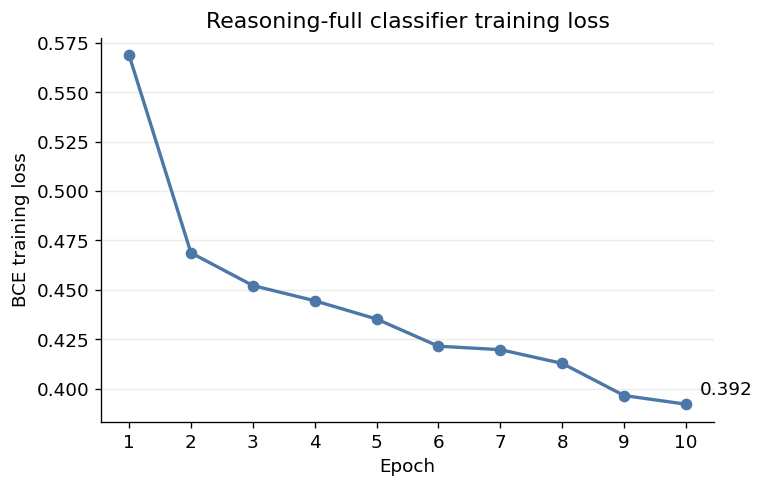

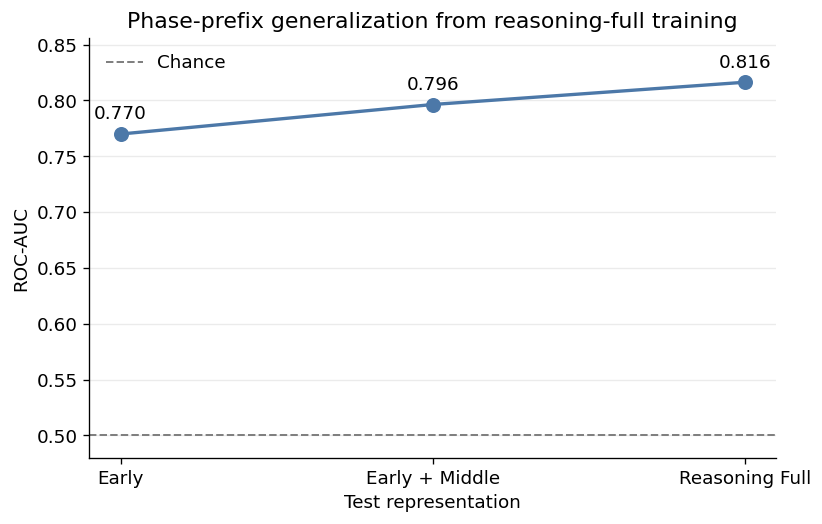

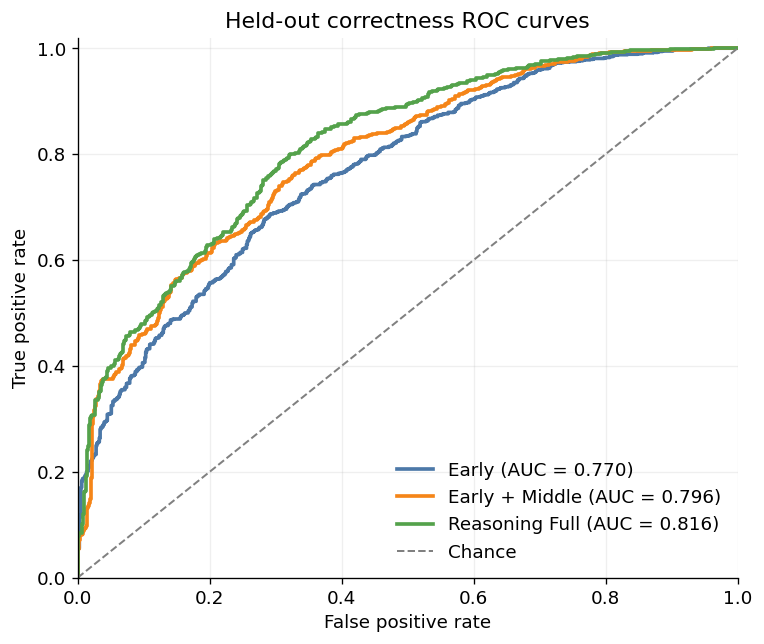

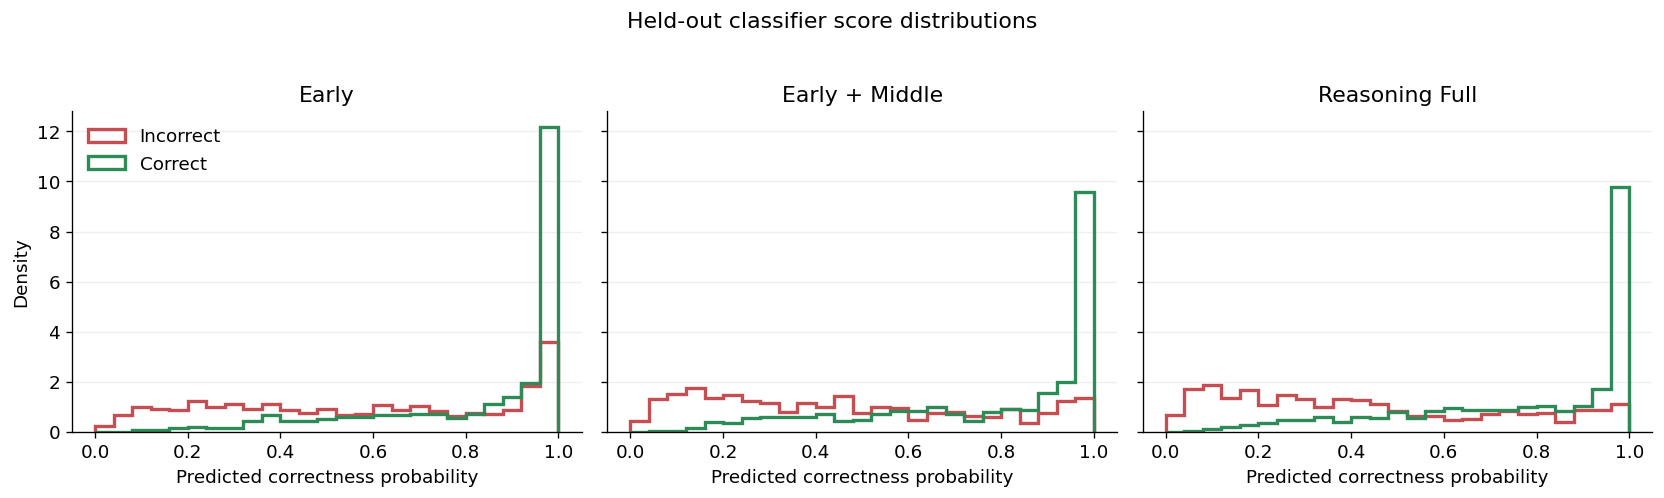

Saved figures to: /content/gdrive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/probe_training_initial_reasoning_phase/figures


In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score, roc_curve


# ------------------------------------------------------------------
# Load saved artifacts
# ------------------------------------------------------------------

OUTPUT_DIR = Path(
    "/content/gdrive/MyDrive/"
    "gemma3_1b_it_gsm8k_raw26_v3_lean/"
    "probe_training_initial_reasoning_phase"
)

FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

HISTORY_PATH = OUTPUT_DIR / "reasoning_full_training_loss.csv"
METRICS_PATH = OUTPUT_DIR / "reasoning_phase_generalization_metrics.csv"
PREDICTIONS_PARQUET_PATH = OUTPUT_DIR / "test_rollout_predictions.parquet"
PREDICTIONS_CSV_PATH = OUTPUT_DIR / "test_rollout_predictions.csv"

TRAINING_HISTORY = pd.read_csv(HISTORY_PATH)
METRICS = pd.read_csv(METRICS_PATH)

if PREDICTIONS_PARQUET_PATH.is_file():
    TEST_PREDICTIONS = pd.read_parquet(PREDICTIONS_PARQUET_PATH)
elif PREDICTIONS_CSV_PATH.is_file():
    TEST_PREDICTIONS = pd.read_csv(PREDICTIONS_CSV_PATH)
else:
    raise FileNotFoundError("No saved test-prediction artifact was found.")


# ------------------------------------------------------------------
# Validate the loaded analysis data
# ------------------------------------------------------------------

CONDITION_ORDER = [
    "early",
    "early_middle",
    "reasoning_full",
]

CONDITION_LABELS = {
    "early": "Early",
    "early_middle": "Early + Middle",
    "reasoning_full": "Reasoning Full",
}

required_prediction_columns = {
    "key",
    "prompt_id",
    "target",
    "condition",
    "predicted_probability",
}

missing_columns = (
    required_prediction_columns
    - set(TEST_PREDICTIONS.columns)
)

if missing_columns:
    raise ValueError(
        "Prediction artifact is missing columns: "
        f"{sorted(missing_columns)}"
    )

actual_conditions = set(
    TEST_PREDICTIONS["condition"].unique()
)

if actual_conditions != set(CONDITION_ORDER):
    raise ValueError(
        "Unexpected prediction conditions: "
        f"{sorted(actual_conditions)}"
    )

condition_counts = (
    TEST_PREDICTIONS["condition"]
    .value_counts()
)

if condition_counts.nunique() != 1:
    raise ValueError(
        "Prediction conditions have unequal rollout counts: "
        f"{condition_counts.to_dict()}"
    )

if not np.isfinite(
    TEST_PREDICTIONS["predicted_probability"]
).all():
    raise ValueError(
        "Prediction probabilities contain non-finite values."
    )


# ------------------------------------------------------------------
# Construct a compact phase summary
# ------------------------------------------------------------------

TEST_PHASE_SUMMARY = (
    METRICS.loc[METRICS["split"].eq("test")]
    .set_index("condition")
    .loc[CONDITION_ORDER]
    .reset_index()
)

TEST_PHASE_SUMMARY["display_condition"] = (
    TEST_PHASE_SUMMARY["condition"]
    .map(CONDITION_LABELS)
)

early_auc = float(
    TEST_PHASE_SUMMARY.loc[
        TEST_PHASE_SUMMARY["condition"].eq("early"),
        "roc_auc",
    ].iloc[0]
)

TEST_PHASE_SUMMARY["auc_difference_vs_early"] = (
    TEST_PHASE_SUMMARY["roc_auc"]
    - early_auc
)

display(
    TEST_PHASE_SUMMARY[
        [
            "display_condition",
            "roc_auc",
            "accuracy",
            "auc_difference_vs_early",
        ]
    ].rename(
        columns={
            "display_condition": "condition",
        }
    )
)

TEST_PHASE_SUMMARY.to_csv(
    OUTPUT_DIR / "reasoning_phase_analysis_summary.csv",
    index=False,
)


# ------------------------------------------------------------------
# Consistent plot styling
# ------------------------------------------------------------------

COLORS = {
    "early": "#4C78A8",
    "early_middle": "#F58518",
    "reasoning_full": "#54A24B",
    "correct": "#2E8B57",
    "incorrect": "#C44E52",
}

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 200,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


# ------------------------------------------------------------------
# Plot 1: training loss
# ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6.5, 4.2))

ax.plot(
    TRAINING_HISTORY["epoch"],
    TRAINING_HISTORY["training_loss"],
    marker="o",
    linewidth=2,
    color="#4C78A8",
)

final_loss = float(
    TRAINING_HISTORY["training_loss"].iloc[-1]
)

ax.annotate(
    f"{final_loss:.3f}",
    xy=(
        TRAINING_HISTORY["epoch"].iloc[-1],
        final_loss,
    ),
    xytext=(8, 6),
    textcoords="offset points",
)

ax.set(
    xlabel="Epoch",
    ylabel="BCE training loss",
    title="Reasoning-full classifier training loss",
)

ax.set_xticks(
    TRAINING_HISTORY["epoch"]
)

ax.grid(
    axis="y",
    alpha=0.25,
)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "reasoning_full_training_loss.png",
    bbox_inches="tight",
)
plt.show()


# ------------------------------------------------------------------
# Plot 2: held-out ROC-AUC across cumulative phases
# ------------------------------------------------------------------

x_positions = np.arange(
    len(TEST_PHASE_SUMMARY)
)

auc_values = TEST_PHASE_SUMMARY[
    "roc_auc"
].to_numpy()

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(
    x_positions,
    auc_values,
    marker="o",
    markersize=8,
    linewidth=2,
    color="#4C78A8",
)

for x, auc_value in zip(
    x_positions,
    auc_values,
):
    ax.annotate(
        f"{auc_value:.3f}",
        xy=(x, auc_value),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
    )

ax.axhline(
    0.5,
    linestyle="--",
    linewidth=1.2,
    color="gray",
    label="Chance",
)

ax.set_xticks(
    x_positions,
    TEST_PHASE_SUMMARY["display_condition"],
)

ax.set_ylim(
    0.48,
    max(0.85, auc_values.max() + 0.04),
)

ax.set(
    xlabel="Test representation",
    ylabel="ROC-AUC",
    title=(
        "Phase-prefix generalization from "
        "reasoning-full training"
    ),
)

ax.grid(
    axis="y",
    alpha=0.25,
)

ax.legend(
    frameon=False,
)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "reasoning_phase_auc_comparison.png",
    bbox_inches="tight",
)
plt.show()


# ------------------------------------------------------------------
# Plot 3: held-out ROC curves
# ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6.5, 5.5))

for condition in CONDITION_ORDER:
    condition_rows = TEST_PREDICTIONS.loc[
        TEST_PREDICTIONS["condition"].eq(condition)
    ]

    labels = condition_rows[
        "target"
    ].to_numpy()

    probabilities = condition_rows[
        "predicted_probability"
    ].to_numpy()

    fpr, tpr, _ = roc_curve(
        labels,
        probabilities,
    )

    auc_value = roc_auc_score(
        labels,
        probabilities,
    )

    ax.plot(
        fpr,
        tpr,
        linewidth=2.2,
        color=COLORS[condition],
        label=(
            f"{CONDITION_LABELS[condition]} "
            f"(AUC = {auc_value:.3f})"
        ),
    )

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.2,
    color="gray",
    label="Chance",
)

ax.set(
    xlabel="False positive rate",
    ylabel="True positive rate",
    title="Held-out correctness ROC curves",
    xlim=(0, 1),
    ylim=(0, 1.02),
)

ax.grid(
    alpha=0.2,
)

ax.legend(
    frameon=False,
    loc="lower right",
)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "reasoning_phase_roc_curves.png",
    bbox_inches="tight",
)
plt.show()


# ------------------------------------------------------------------
# Plot 4: score distributions by correctness
# ------------------------------------------------------------------

probability_bins = np.linspace(
    0,
    1,
    26,
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(14, 4),
    sharex=True,
    sharey=True,
)

for axis, condition in zip(
    axes,
    CONDITION_ORDER,
):
    condition_rows = TEST_PREDICTIONS.loc[
        TEST_PREDICTIONS["condition"].eq(condition)
    ]

    incorrect_scores = condition_rows.loc[
        condition_rows["target"].eq(0),
        "predicted_probability",
    ]

    correct_scores = condition_rows.loc[
        condition_rows["target"].eq(1),
        "predicted_probability",
    ]

    axis.hist(
        incorrect_scores,
        bins=probability_bins,
        density=True,
        histtype="step",
        linewidth=2,
        color=COLORS["incorrect"],
        label="Incorrect",
    )

    axis.hist(
        correct_scores,
        bins=probability_bins,
        density=True,
        histtype="step",
        linewidth=2,
        color=COLORS["correct"],
        label="Correct",
    )

    axis.set_title(
        CONDITION_LABELS[condition]
    )

    axis.set_xlabel(
        "Predicted correctness probability"
    )

    axis.grid(
        axis="y",
        alpha=0.2,
    )

axes[0].set_ylabel(
    "Density"
)

axes[0].legend(
    frameon=False,
)

fig.suptitle(
    "Held-out classifier score distributions",
    y=1.03,
)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "reasoning_phase_score_distributions.png",
    bbox_inches="tight",
)
plt.show()


print("Saved figures to:", FIGURE_DIR)